# TS-SatFire v5 · Détection du feu actif


## 1. Exécution sur Kaggle
Ajouter le jeu de données TS-SatFire de z789456sx

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("rasterio") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])

from pathlib import Path
import json
import time
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import rasterio
from rasterio.enums import Resampling
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, FileLink
from tqdm.auto import tqdm

started = time.perf_counter()
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("CPU detected: enable a Kaggle GPU for the estimated runtime.")

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Paramètres

In [2]:
SEED = 42
DATA_FRACTION = 1.0
SIZE = 256
BASELINE_SIZE = 128
EPOCHS = 30
PATIENCE = 8
BATCH_SIZE = 8
DICE_WEIGHT = 0.9
SAVE_CHECKPOINT = False
RESTORE_FROM = None  # dossier v5 décompressé, section 15
RUN_CV = False
CV_FOLDS = 3

INPUT = Path("/kaggle/input")
OUTPUT = Path("/kaggle/working/satfire_v5_results")
if OUTPUT.exists() and any(OUTPUT.iterdir()):
    from uuid import uuid4
    OUTPUT = OUTPUT.with_name(OUTPUT.name + "_" + uuid4().hex[:8])
OUTPUT.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["Forêt", "Feu", "Brûlé", "Autre"]
N_CLASSES = len(CLASS_NAMES)
OTHER = 3                    # identifiant de la classe « Autre »
FOCUS = [1, 2]               # feu et brûlé : critère de sélection du modèle
IGNORE = 255
COLORS = ["#238443", "#ef3b2c", "#54278f", "#d8b365"]
CMAP = ListedColormap(COLORS)
CMAP.set_bad("#dddddd")

LANDCOVER_FOREST_CODES = [1, 2, 3, 4, 5]
LANDCOVER_VALID_CODES = list(range(1, 18))  # MODIS LC_Type1 / IGBP
LANDCOVER_FILL_CODES = [255]  # valeurs traitées comme « occupation du sol inconnue » (voir section 3)


assert 0 < DATA_FRACTION <= 1
tf.keras.utils.set_random_seed(SEED)

## 3. Modèle et décision
Les quatre classes contribuent à l’entropie croisée pondérée. Le terme Dice reste appliqué au feu et au brûlé. Le meilleur modèle maximise l’IoU du feu actif en validation. Les lots sont normalisés avec les statistiques du groupe d’entraînement courant.

In [3]:
# ---------- normalisation, poids de classes, augmentation, lots ----------
def channel_statistics(images, indices):
    total = np.zeros(6, dtype=np.float64)
    square = np.zeros(6, dtype=np.float64)
    count = np.zeros(6, dtype=np.int64)
    for i in indices:
        image = images[i].astype("float64")
        finite = np.isfinite(image)
        image = np.where(finite, image, 0)
        total += image.sum(axis=(0, 1))
        square += np.square(image).sum(axis=(0, 1))
        count += finite.sum(axis=(0, 1))
    assert np.all(count > 0), "Une bande n'a aucune valeur finie à l'entraînement."
    mean = total / count
    std = np.sqrt(np.maximum(square / count - mean**2, 1e-12))
    return mean.astype("float32"), std.astype("float32")

def class_weights_for(indices):
    labels = Y[indices]
    counts = np.bincount(labels[labels != IGNORE], minlength=N_CLASSES)
    assert np.all(counts > 0), "Une classe est absente de l'ensemble d'entraînement."
    return np.minimum(np.sqrt(counts.max() / counts), 10).astype("float32"), counts

def augment_pair(image, mask, flip_horizontal, flip_vertical, turns, rng):
    # Augmentation spatiale (image et masque)
    if flip_horizontal:
        image, mask = np.flip(image, 1), np.flip(mask, 1)
    if flip_vertical:
        image, mask = np.flip(image, 0), np.flip(mask, 0)
    image = np.rot90(image, turns).copy()
    mask = np.rot90(mask, turns).copy()
    # Augmentation spectrale (bandes normalisées)
    image = image * rng.uniform(0.9, 1.1)
    band_gain = rng.uniform(0.95, 1.05, size=(1, 1, 6))
    band_offset = rng.uniform(-0.05, 0.05, size=(1, 1, 6))
    image = image * band_gain + band_offset
    # Faible bruit d'observation
    noise = rng.normal(0, 0.02, size=image.shape).astype("float32")
    image = (image + noise).astype("float32")
    return image, mask

def normalize(raw, mean, std):
    normalized = (raw - mean) / std
    return np.nan_to_num(normalized, copy=False, nan=0.0, posinf=0.0, neginf=0.0)

def make_batches(indices, training=False, seed=SEED):
    rng = np.random.default_rng(seed)
    def samples():
        order = rng.permutation(indices) if training else indices
        for i in order:
            image, mask = normalize(X[i], mean, std), Y[i]
            if training:
                image, mask = augment_pair(image, mask, rng.random() < 0.5,
                                           rng.random() < 0.5, int(rng.integers(4)), rng)
            yield image, mask.astype("int32")
    signature = (tf.TensorSpec((SIZE, SIZE, 6), tf.float32),
                 tf.TensorSpec((SIZE, SIZE), tf.int32))
    dataset = tf.data.Dataset.from_generator(samples, output_signature=signature)
    dataset = dataset.apply(tf.data.experimental.assert_cardinality(len(indices)))
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# ---------- modèle et perte ----------
def build_model():
    def block(x, filters, dilation):
        x = layers.Conv2D(filters, 3, padding="same", dilation_rate=dilation, use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        return layers.ReLU()(x)

    inputs = layers.Input(shape=(SIZE, SIZE, 6))
    x = block(inputs, 32, 1)
    x = block(x, 32, 2)
    x = block(x, 64, 4)
    x = block(x, 64, 8)
    x = block(x, 64, 16)
    x = block(x, 32, 1)
    outputs = layers.Conv2D(N_CLASSES, 1, padding="same", activation="softmax")(x)
    return models.Model(inputs, outputs)

class CombinedLoss(tf.keras.losses.Loss):
    """Entropie croisée pondérée + perte Dice (feu et brûlé). Les pixels 255 sont ignorés."""
    def __init__(self, class_weights, dice_weight=0.5, name="ce_dice"):
        super().__init__(name=name)
        self.class_weights = tf.constant(class_weights, tf.float32)
        self.dice_weight = dice_weight

    def call(self, y_true, y_pred):
        y_true = tf.cast(y_true, tf.int32)
        valid = tf.cast(y_true != IGNORE, tf.float32)
        target = tf.where(y_true == IGNORE, 0, y_true)
        weight = valid * tf.gather(self.class_weights, target)

        pixel_ce = tf.keras.losses.sparse_categorical_crossentropy(target, y_pred)
        ce = tf.reduce_sum(pixel_ce * weight) / tf.maximum(tf.reduce_sum(weight), 1.0)

        mask = valid[..., None]
        onehot = tf.one_hot(target, N_CLASSES) * mask
        probs = y_pred * mask
        inter = tf.reduce_sum(onehot * probs, axis=[0, 1, 2])
        total = tf.reduce_sum(onehot, axis=[0, 1, 2]) + tf.reduce_sum(probs, axis=[0, 1, 2])
        dice = (2.0 * inter + 1.0) / (total + 1.0)
        return ce + self.dice_weight * (1.0 - tf.reduce_mean(tf.gather(dice, FOCUS)))

# ---------- métriques ----------
def confusion(truth, predicted):
    index = truth.astype("int64") * N_CLASSES + predicted
    return np.bincount(index, minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)

def class_scores(cm):
    tp = np.diag(cm).astype(float)
    actual, guessed = cm.sum(1), cm.sum(0)
    def divide(a, b):
        return np.divide(a, b, out=np.full(N_CLASSES, np.nan), where=b > 0)
    return {"precision": divide(tp, guessed), "recall": divide(tp, actual),
            "f1": divide(2 * tp, actual + guessed),
            "iou": divide(tp, actual + guessed - tp),
            "accuracy": float(tp.sum() / cm.sum()), "support": actual}

def evaluate_iou(predictor, indices):
    cm = np.zeros((N_CLASSES, N_CLASSES), dtype=np.int64)
    for start in range(0, len(indices), BATCH_SIZE):
        batch = indices[start:start + BATCH_SIZE]
        predicted = np.asarray(predictor(normalize(X[batch], mean, std), training=False)).argmax(-1)
        target = Y[batch]
        valid = target != IGNORE
        cm += confusion(target[valid], predicted[valid])
    return class_scores(cm)["iou"]

def predict_probs(net, indices):
    parts = []
    for start in range(0, len(indices), BATCH_SIZE):
        batch = indices[start:start + BATCH_SIZE]
        parts.append(np.asarray(net(normalize(X[batch], mean, std), training=False)))
    return np.concatenate(parts)

# ---------- entraînement ----------
class ValidationIoU(tf.keras.callbacks.Callback):
    def __init__(self, indices, verbose=True):
        super().__init__()
        self.indices, self.verbose = indices, verbose
    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        s = evaluate_iou(self.model, self.indices)
        (logs["val_forest_iou"], logs["val_fire_iou"],
         logs["val_burned_iou"], logs["val_other_iou"]) = [float(np.nan_to_num(v)) for v in s]
        focus = s[FOCUS]
        logs["val_target_iou"] = float(np.nanmean(focus)) if np.isfinite(focus).any() else 0.0
        if self.verbose:
            print(f"IoU validation feu : {s[1]:.3f} | brûlé : {s[2]:.3f} | autre : {np.nan_to_num(s[3]):.3f}")

class EpochTimer(tf.keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        seconds = time.perf_counter() - self.start
        print(f"Époque : {seconds:.1f} s | au plus {(EPOCHS - epoch - 1) * seconds / 60:.1f} min restantes")

def train_model(train_indices, val_indices, tag, verbose=2):
    tf.keras.backend.clear_session()
    weights, _ = class_weights_for(train_indices)
    net = build_model()
    net.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                loss=CombinedLoss(weights, DICE_WEIGHT))
    path = OUTPUT / f"best_model_{tag}.keras"
    callbacks = [
        ValidationIoU(val_indices, verbose=verbose > 0),
        tf.keras.callbacks.ModelCheckpoint(str(path), monitor="val_fire_iou", mode="max", save_best_only=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_fire_iou", mode="max", patience=PATIENCE),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_fire_iou", mode="max", factor=0.5,
                                             patience=3, min_lr=1e-5),
        tf.keras.callbacks.CSVLogger(str(OUTPUT / f"epoch_log_{tag}.csv")),
    ]
    if verbose > 0:
        callbacks.append(EpochTimer())
    # Les IoU de validation sont calculés par ValidationIoU : pas de passe de validation Keras en double.
    history = net.fit(make_batches(train_indices, training=True, seed=SEED),
                      epochs=EPOCHS, callbacks=callbacks, verbose=verbose)
    table = pd.DataFrame(history.history, index=range(1, len(history.history["loss"]) + 1))
    table.index.name = "epoch"
    return models.load_model(path, compile=False), table

# ---------- vérifications rapides ----------
# Changer la prédiction sur un pixel ignoré ne doit pas changer la perte.
_check = CombinedLoss(np.array([1.0, 2.0, 3.0, 1.5], dtype="float32"), DICE_WEIGHT)
_y = np.array([[[0, 1, 2], [3, IGNORE, 3]]], dtype="int32")
_p1 = np.full((1, 2, 3, N_CLASSES), 1 / N_CLASSES, dtype="float32")
_p2 = _p1.copy()
_p2[0, 1, 1] = [0.97, 0.01, 0.01, 0.01]
assert abs(float(_check(_y, _p1)) - float(_check(_y, _p2))) < 1e-6
del _check, _y, _p1, _p2
build_model().summary()

def decide(probs, fire_factor=1.0, forest_factor=1.0):
    labels = np.argmax(probs, axis=-1).astype("uint8")
    active_group = (labels == 1) | (labels == 2)
    forest_group = ~active_group
    if fire_factor != 1.0:
        fire_wins = probs[..., 1] * fire_factor >= probs[..., 2]
        labels[active_group] = np.where(fire_wins[active_group], 1, 2)
    if forest_factor != 1.0:
        forest_wins = probs[..., 0] * forest_factor >= probs[..., 3]
        labels[forest_group] = np.where(forest_wins[forest_group], 0, 3)
    return labels

def tune_decisions(net, indices):
    # Une passe réseau, puis accumulation des matrices par lot.
    factors = [1.0, 0.9, 1.1, 0.8, 1.25, 0.67, 1.5, 0.5, 2.0]
    candidates = [(f, 1.0) for f in factors] + [(1.0, f) for f in factors[1:]]
    matrices = {key: np.zeros((4, 4), dtype=np.int64) for key in candidates}
    for start in range(0, len(indices), BATCH_SIZE):
        batch = indices[start:start + BATCH_SIZE]
        y = Y[batch]
        valid = y != IGNORE
        probs = predict_probs(net, batch)[valid]
        for key in candidates:
            matrices[key] += confusion(y[valid], decide(probs, *key))
    records = []
    for (ff, fg), matrix in matrices.items():
        scores = class_scores(matrix)
        records.append(dict(fire_factor=ff, forest_factor=fg, fire_f1=scores["f1"][1],
                            fire_precision=scores["precision"][1], fire_recall=scores["recall"][1],
                            forest_iou=scores["iou"][0]))
    table = pd.DataFrame(records)
    fire = table[table.forest_factor == 1].dropna(subset=["fire_f1"])
    forest = table[table.fire_factor == 1].dropna(subset=["forest_iou"])
    if fire.empty or forest.empty:
        raise ValueError("Validation insuffisante pour régler les deux décisions.")
    return {"fire_factor": float(fire.loc[fire.fire_f1.idxmax(), "fire_factor"]),
            "forest_factor": float(forest.loc[forest.forest_iou.idxmax(), "forest_factor"])}, table


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 256, 256, 6)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 256, 256, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 256, 256, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256, 256, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 256, 256, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 256, 256, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256, 256, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 256, 256, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 256, 256, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256, 256, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 256, 256, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 256, 256, 32)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 256, 256, 4)    │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,820 (479.77 KB)

 Trainable params: 122,244 (477.52 KB)

 Non-trainable params: 576 (2.25 KB)

## 4. Sélection des événements

Pour chaque événement, une image VIIRS (`VIIRS_Day`) est associée au fichier `FirePred` de même date, qui contient l'occupation du sol (bande 14). On choisit au hasard `DATA_FRACTION` des événements (tous, par défaut) avant de lire les pixels.

In [4]:
folders = sorted(p for p in INPUT.rglob("VIIRS_Day") if p.is_dir())
rows = []
for folder in folders:
    for image in sorted(folder.glob("*.tif")):
        auxiliary_name = image.name.replace("_VIIRS_Day", "_FirePred")
        auxiliary = folder.parent / "FirePred" / auxiliary_name
        if auxiliary.is_file():
            rows.append({"event": folder.parent.name, "image": str(image),
                         "auxiliary": str(auxiliary), "event_path": str(folder.parent)})

assert rows, "Attach TS-SatFire with matching VIIRS_Day and FirePred folders."
catalog = pd.DataFrame(rows)
assert catalog.groupby("event").event_path.nunique().max() == 1, "Attach only one dataset copy."
all_events = sorted(catalog.event.unique())
n_selected = max(1, round(len(all_events) * DATA_FRACTION))
assert n_selected >= 10, "Too few events. Attach the complete source dataset; check the dataset version."
selected = sorted(np.random.default_rng(SEED).choice(all_events, n_selected, replace=False).tolist())
files = catalog[catalog.event.isin(selected)].reset_index(drop=True)

selection = {"seed": SEED, "requested_fraction": DATA_FRACTION,
             "eligible_events": len(all_events), "selected_events": selected,
             "actual_event_fraction": n_selected / len(all_events),
             "eligible_matching_dates": len(catalog), "selected_matching_dates": len(files)}
(OUTPUT / "selection.json").write_text(json.dumps(selection, indent=2))
print(f"Events: {n_selected}/{len(all_events)} ({n_selected / len(all_events):.1%})")
print(f"Matching dates: {len(files)}/{len(catalog)} ({len(files) / len(catalog):.1%})")
display(files[["event", "image"]].head())

Events: 178/178 (100.0%)
Matching dates: 3556/3556 (100.0%)


,event,image
0,20562846,/kaggle/input/datasets/z789456sx/ts-satfire/ts...
1,20562846,/kaggle/input/datasets/z789456sx/ts-satfire/ts...
2,20562846,/kaggle/input/datasets/z789456sx/ts-satfire/ts...
3,20562846,/kaggle/input/datasets/z789456sx/ts-satfire/ts...
4,20562846,/kaggle/input/datasets/z789456sx/ts-satfire/ts...


### Vérification des codes d’occupation du sol
La légende utilisée pour la bande 14 est MODIS LC_Type1 (IGBP). Les codes 1 à 5 indiquent la forêt, 6 à 17 les autres terrains. Les codes inattendus et les valeurs ambiguës sont exclus des cibles de fond. Vérifier la légende si le produit d’entrée change. [Table des classes](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MCD12Q1)

In [5]:
def landcover_codes(values):
    finite = np.isfinite(values)
    safe = np.where(finite, values, 0)
    rounded = np.rint(safe)
    valid = finite & (np.abs(safe - rounded) < 0.05) & np.isin(rounded, LANDCOVER_VALID_CODES)
    return np.where(valid, rounded, IGNORE).astype("uint8")

sample = files.auxiliary.sample(min(40, len(files)), random_state=SEED)
totals = np.zeros(256, dtype=np.int64)
for path in sample:
    with rasterio.open(path) as aux:
        if aux.count >= 14:
            values = aux.read(14, masked=True, out_dtype="float32").filled(np.nan)
            totals += np.bincount(landcover_codes(values).ravel(), minlength=256)
display(pd.Series(totals[totals > 0], index=np.flatnonzero(totals), name="pixels (255 = inconnu)"))

1     1964036
2       54081
4        7224
5       36436
6       64287
7      808498
8     1941685
9      984634
10    4735371
11      27763
12     723995
13     196234
14       9001
15       2237
16     135519
17     474849
Name: pixels (255 = inconnu), dtype: int64

## 5. Construction des masques forêt / feu / brûlé / autre

| Identifiant | Classe | Règle |
|---|---|---|
| 0 | Forêt | Occupation du sol « forêt » (codes 1 à 5), sans feu ni zone brûlée annotés |
| 1 | Feu | Annotation positive dans la bande 7 (prioritaire sur brûlé) |
| 2 | Brûlé | Identifiant de périmètre positif dans la bande 8, sans feu actif |
| 3 | Autre | Occupation du sol connue mais non forestière, sans feu ni zone brûlée annotés |
| 255 | Ignoré | Observation manquante, occupation du sol absente ou inconnue, étiquette incertaine |

Les pixels de feu et de brûlé gardent leur classe quelle que soit l'occupation du sol. Seules les six bandes d'observation entrent dans le réseau ; les bandes 7 et 8 et l'occupation du sol servent uniquement à fabriquer la cible.

In [6]:
def has_annotations(active, burned):
    # Check BEFORE resizing: small annotations can disappear at 128 x 128.
    return (np.any(np.isfinite(active) & (active > 0)) and
            np.any(np.isfinite(burned) & (burned > 0)))

def make_mask(image, active, burned, landcover):
    valid = np.isfinite(image).all(axis=-1)
    fire = np.isfinite(active) & (active > 0)
    scar = np.isfinite(burned) & (burned > 0)
    # This decoder is called only after the native-resolution annotation check.
    valid &= (np.isnan(active) | fire) & (np.isnan(burned) | scar)
    codes = landcover_codes(landcover)
    forest = np.isin(codes, LANDCOVER_FOREST_CODES)
    other = (codes != IGNORE) & ~forest

    mask = np.full(active.shape, IGNORE, dtype=np.uint8)
    mask[valid & other & ~fire & ~scar] = OTHER
    mask[valid & forest & ~fire & ~scar] = 0
    mask[valid & scar] = 2
    mask[valid & fire] = 1
    return mask


def has_original_classes(mask):
    # Au moins un pixel forêt, feu ou brûlé (même critère d'éligibilité qu'en version 3).
    return bool(np.any((mask != IGNORE) & (mask != OTHER)))


def aligned_cover(day, aux, size):
    from affine import Affine
    from rasterio.vrt import WarpedVRT

    transform = day.transform * Affine.scale(day.width / size, day.height / size)
    with WarpedVRT(aux, crs=day.crs, transform=transform, width=size, height=size,
                   resampling=Resampling.nearest, dtype="float32", nodata=np.nan) as aligned:
        landcover = aligned.read(14, masked=True).filled(np.nan)
    assert np.isfinite(landcover).any(), f"No land-cover coverage for {day.name}"
    return landcover

def read_grid(day, aux, size):
    raw = day.read(out_shape=(8, size, size), out_dtype="float32",
                   resampling=Resampling.nearest, masked=True).filled(np.nan)
    landcover = aligned_cover(day, aux, size)
    image = np.moveaxis(raw[:6], 0, -1)
    return image, make_mask(image, raw[6], raw[7], landcover)

def read_example(image_path, auxiliary_path):
    with rasterio.open(image_path) as day, rasterio.open(auxiliary_path) as aux:
        if day.count != 8 or aux.count < 14:
            return None, "missing required bands"
        labels = day.read([7, 8], out_dtype="float32", masked=True).filled(np.nan)
        if not has_annotations(labels[0], labels[1]):
            return None, "empty active-fire or burned-area annotation layer"
        assert day.crs is not None and aux.crs is not None, "Missing raster CRS"
        _, baseline_mask = read_grid(day, aux, BASELINE_SIZE)
        if not has_original_classes(baseline_mask):
            return None, "no valid target pixels at baseline resolution"
        image, mask = read_grid(day, aux, SIZE)
        # The caller records baseline eligibility before excluding an empty new grid.
    return (image, mask), ""

In [7]:
images, masks, kept, excluded = [], [], [], []
baseline_events = set()
for i, row in tqdm(files.iterrows(), total=len(files), desc="Reading selected dates"):
    sample, reason = read_example(row.image, row.auxiliary)
    if sample is None:
        excluded.append({"image": row.image, "reason": reason})
        continue
    baseline_events.add(row.event)
    image, mask = sample
    if not has_original_classes(mask):
        excluded.append({"image": row.image, "reason": f"no valid target pixels at {SIZE}px resolution"})
        continue
    images.append(image)
    masks.append(mask)
    kept.append(i)

pd.DataFrame(excluded, columns=["image", "reason"]).to_csv(OUTPUT / "excluded_dates.csv", index=False)
if excluded:
    print("Excluded dates by reason:")
    print(pd.DataFrame(excluded).reason.value_counts())
assert images, "No usable dates. Check the input version, band values and nodata settings."
X, Y = np.stack(images), np.stack(masks)
files = files.iloc[kept].reset_index(drop=True)
del images, masks
print("Images:", X.shape, "Masks:", Y.shape, "Excluded dates:", len(excluded))
print("Usable events:", files.event.nunique(), "of", n_selected, "selected events")
print(f"Approximate image-array memory: {X.nbytes / 1024**2:.0f} MB")
print("Retained target pixels:", dict(zip(CLASS_NAMES,
      np.bincount(Y[Y != IGNORE], minlength=N_CLASSES).tolist())))

Reading selected dates:   0%|          | 0/3556 [00:00<?, ?it/s]

Excluded dates by reason:
reason
empty active-fire or burned-area annotation layer    1150
missing required bands                                 50
no valid target pixels at baseline resolution           9
no valid target pixels at 256px resolution              1
Name: count, dtype: int64
Images: (2346, 256, 256, 6) Masks: (2346, 256, 256) Excluded dates: 1210
Usable events: 140 of 178 selected events
Approximate image-array memory: 3519 MB
Retained target pixels: {'Forêt': 23587656, 'Feu': 283777, 'Brûlé': 1484104, 'Autre': 128036670}


## 6. Découpage par événement

Environ 70 % des événements servent à l'entraînement, 15 % à la validation (choix du meilleur modèle) et 15 % au test. Toutes les dates d'un même événement restent dans le même groupe. Ce découpage est pédagogique, ce n'est pas le découpage officiel du jeu de données.

In [8]:
events = sorted(baseline_events)
assert len(events) >= 6, "Fewer than six jointly annotated events; inspect excluded_dates.csv."
if len(events) < 10:
    print("Small-sample notice: fewer than ten usable events; test results will be unstable.")
train_events, rest = train_test_split(events, test_size=0.30, random_state=SEED)
val_events, test_events = train_test_split(rest, test_size=0.50, random_state=SEED)
split = {"train": train_events, "validation": val_events, "test": test_events}
lookup = {event: name for name, group in split.items() for event in group}
files["split"] = files.event.map(lookup)
train_idx = np.flatnonzero(files.split == "train")
val_idx = np.flatnonzero(files.split == "validation")
test_idx = np.flatnonzero(files.split == "test")
assert not (set(train_events) & set(val_events) or set(train_events) & set(test_events)
            or set(val_events) & set(test_events))

distribution = []
for name, idx in [("train", train_idx), ("validation", val_idx), ("test", test_idx)]:
    assert len(idx) > 0, f"No usable dates remain in {name}; inspect excluded_dates.csv."
    counts = np.bincount(Y[idx][Y[idx] != IGNORE], minlength=N_CLASSES)
    distribution.append({"split": name, "images": len(idx), "events": files.event.iloc[idx].nunique(),
                         **dict(zip(CLASS_NAMES, counts.tolist()))})
    if name in ["train", "validation"]:
        assert np.all(counts > 0), f"A class is absent in {name}; the validation objective cannot be used."
    elif np.any(counts == 0):
        print(f"Note: {name} has a missing class; interpret its metrics with care.")
display(pd.DataFrame(distribution))
pd.DataFrame(distribution).to_csv(OUTPUT / "class_counts.csv", index=False)
files.to_csv(OUTPUT / "data_split.csv", index=False)
(OUTPUT / "event_split.json").write_text(json.dumps(split, indent=2))

,split,images,events,Forêt,Feu,Brûlé,Autre
0,train,1758,98,18427937,207064,1096731,95247178
1,validation,259,21,1681768,26935,76909,15116700
2,test,329,21,3477951,49778,310464,17672792


2770

## 7. Aperçu de l'entrée et de la cible

L'image est affichée en fausses couleurs (trois bandes d'observation). Les pixels gris clair sont ignorés ; la classe Autre est en beige.

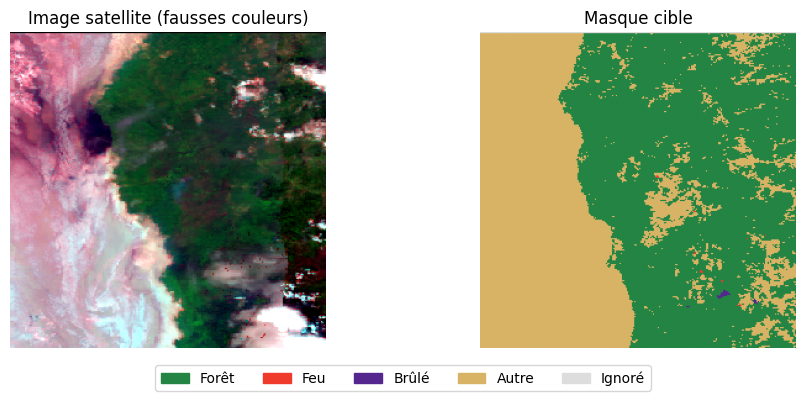

In [9]:
def display_image(image):
    rgb = image[..., [5, 1, 0]].copy()
    low, high = np.nanpercentile(rgb, [2, 98], axis=(0, 1))
    return np.nan_to_num(np.clip((rgb - low) / np.maximum(high - low, 1e-6), 0, 1))

legend = [Patch(color=c, label=n) for c, n in zip(COLORS, CLASS_NAMES)]
legend.append(Patch(color="#dddddd", label="Ignoré"))
example = train_idx[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(display_image(X[example]))
axes[0].set_title("Image satellite (fausses couleurs)")
axes[1].imshow(np.ma.masked_equal(Y[example], IGNORE), cmap=CMAP, vmin=0, vmax=N_CLASSES - 1)
axes[1].set_title("Masque cible")
for ax in axes:
    ax.axis("off")
fig.legend(handles=legend, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.savefig(OUTPUT / "input_example.png", dpi=150)
plt.show()

## 8. Statistiques des six bandes sur les événements d’entraînement

In [10]:
mean, std = channel_statistics(X, train_idx)
np.savez(OUTPUT / "normalization.npz", mean=mean, std=std)

class_weights, counts = class_weights_for(train_idx)
print("Poids de classes :", {n: float(w) for n, w in zip(CLASS_NAMES, class_weights.round(2))})

Poids de classes : {'Forêt': 2.2699999809265137, 'Feu': 10.0, 'Brûlé': 9.319999694824219, 'Autre': 1.0}


## 9. Entraînement et sélection du meilleur modèle

Le test n'intervient ni dans l'arrêt anticipé, ni dans la réduction du taux d'apprentissage, ni dans le choix du modèle. Le meilleur modèle (et non le dernier) est rechargé à la fin. La fonction `train_model` est la même pour le modèle principal et pour les plis de validation croisée.

In [11]:
training_started = time.perf_counter()
model, history_table = train_model(train_idx, val_idx, "main")
training_minutes = (time.perf_counter() - training_started) / 60
history_table.to_csv(OUTPUT / "training_history.csv")
best_epoch = int(history_table.val_fire_iou.idxmax())
print(f"Entraînement : {training_minutes:.1f} min | époques : {len(history_table)} | meilleure époque : {best_epoch}")

Epoch 1/30


E0000 00:00:1794962347.011880      72 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794962352.747298      72 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794962434.315713      69 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1794962434.805257      69 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


IoU validation feu : 0.041 | brûlé : 0.111 | autre : 0.825
Époque : 107.5 s | au plus 52.0 min restantes
220/220 - 108s - 489ms/step - loss: 1.5495 - val_forest_iou: 0.3428 - val_fire_iou: 0.0407 - val_burned_iou: 0.1106 - val_other_iou: 0.8248 - val_target_iou: 0.0757 - learning_rate: 0.0010
Epoch 2/30
IoU validation feu : 0.343 | brûlé : 0.186 | autre : 0.906
Époque : 62.7 s | au plus 29.3 min restantes
220/220 - 63s - 285ms/step - loss: 1.1822 - val_forest_iou: 0.4251 - val_fire_iou: 0.3432 - val_burned_iou: 0.1862 - val_other_iou: 0.9057 - val_target_iou: 0.2647 - learning_rate: 0.0010
Epoch 3/30
IoU validation feu : 0.376 | brûlé : 0.116 | autre : 0.894
Époque : 61.5 s | au plus 27.7 min restantes
220/220 - 61s - 279ms/step - loss: 0.9888 - val_forest_iou: 0.4490 - val_fire_iou: 0.3761 - val_burned_iou: 0.1163 - val_other_iou: 0.8936 - val_target_iou: 0.2462 - learning_rate: 0.0010
Epoch 4/30
IoU validation feu : 0.411 | brûlé : 0.219 | autre : 0.868
Époque : 56.6 s | au plus 24.5

## 10. Courbes d'apprentissage

La perte (pondérée, avec terme Dice) n'est pas comparable à celle des versions précédentes. Le meilleur modèle est celui qui a le meilleur IoU de validation moyen feu/brûlé, pas celui qui a la perte la plus basse.

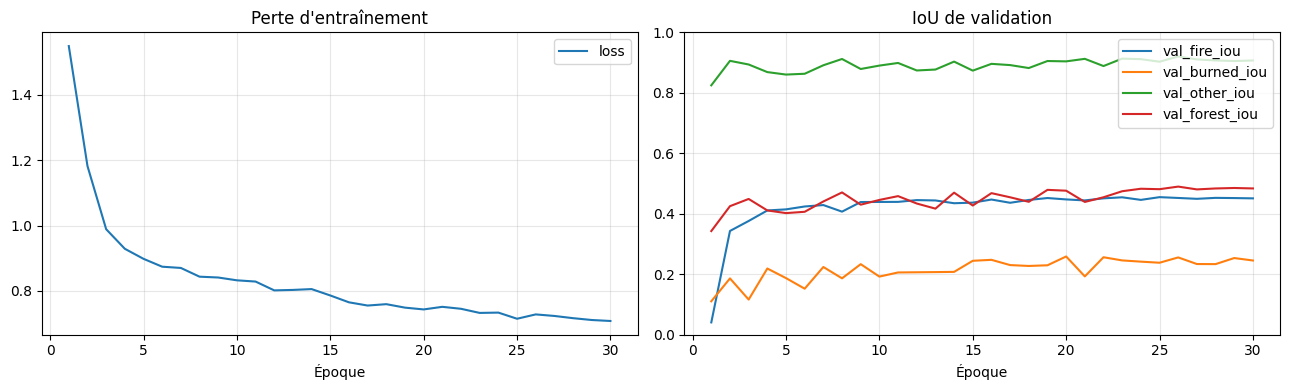

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
history_table[["loss"]].plot(ax=axes[0], title="Perte d'entraînement")
history_table[["val_fire_iou", "val_burned_iou", "val_other_iou", "val_forest_iou"]].plot(
    ax=axes[1], title="IoU de validation")
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.set_xlabel("Époque")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT / "training_curves.png", dpi=150)
plt.show()

## 11. Réglage en validation et évaluation finale
Former deux groupes selon le gagnant argmax initial. Dans le groupe feu/brûlé, choisir le facteur de feu qui maximise le F1 feu. Dans le groupe forêt/autre, choisir le facteur de forêt qui maximise l’IoU forêt. Le second réglage ne change aucune décision feu/brûlé. Un facteur de 1 conserve le choix initial. Afficher aussi la précision et le rappel pour juger le compromis. Les seuils sont appliqués une seule fois au test après sélection.

,fire_factor,forest_factor,fire_f1,fire_precision,fire_recall,forest_iou
0,1.00,1.00,0.6254,0.6632,0.5916,0.4813
1,0.90,1.00,0.6250,0.6661,0.5888,0.4813
2,1.10,1.00,0.6256,0.6606,0.5941,0.4813
3,0.80,1.00,0.6247,0.6695,0.5855,0.4813
4,1.25,1.00,0.6257,0.6573,0.5970,0.4813
5,0.67,1.00,0.6243,0.6750,0.5806,0.4813
6,1.50,1.00,0.6253,0.6514,0.6013,0.4813
7,0.50,1.00,0.6233,0.6844,0.5723,0.4813
8,2.00,1.00,0.6251,0.6423,0.6089,0.4813
9,1.00,0.90,0.6254,0.6632,0.5916,0.4855


Paramètres figés : {'fire_factor': 1.25, 'forest_factor': 0.67}


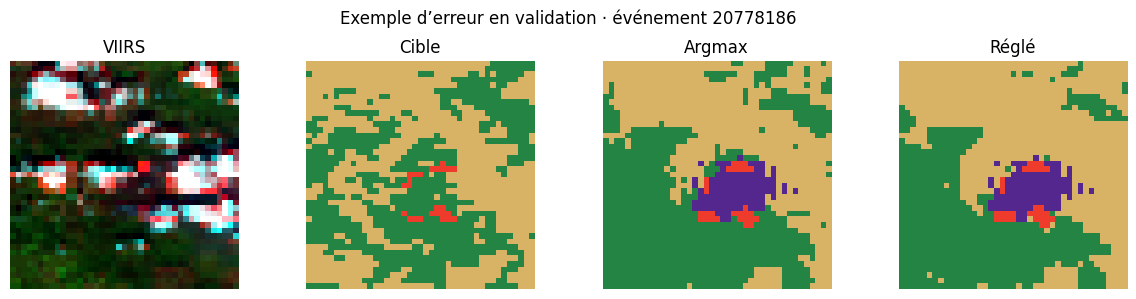

,règle,précision feu,rappel feu,F1 feu,IoU forêt,IoU feu,IoU brûlé,feu → brûlé,brûlé → feu,forêt → autre,autre → forêt
0,argmax,0.660393,0.735204,0.695794,0.587030,0.533500,0.480330,8428,9120,741250,1074186
1,validation,0.653865,0.740508,0.694495,0.577157,0.531974,0.479885,8164,9569,973068,759759


,classe,précision,rappel,F1,IoU,pixels_test
0,Forêt,0.7600,0.7058,0.7319,0.5772,3477951
1,Feu,0.6539,0.7405,0.6945,0.5320,49778
2,Brûlé,0.5957,0.7117,0.6485,0.4799,310464
3,Autre,0.9416,0.9513,0.9464,0.8983,17672792


,test
accuracy,0.9076
IoU moyen (4 classes),0.6218
IoU moyen feu/brûlé,0.5059
IoU forêt,0.5772
IoU feu,0.5320
IoU brûlé,0.4799
IoU autre,0.8983


Référence « tout prédire Autre » : 82.16% d'accuracy
Pixels réellement « Autre » prédits comme : {'Forêt': 0.043, 'Feu': 0.0003, 'Brûlé': 0.0054, 'Autre': 0.9513}


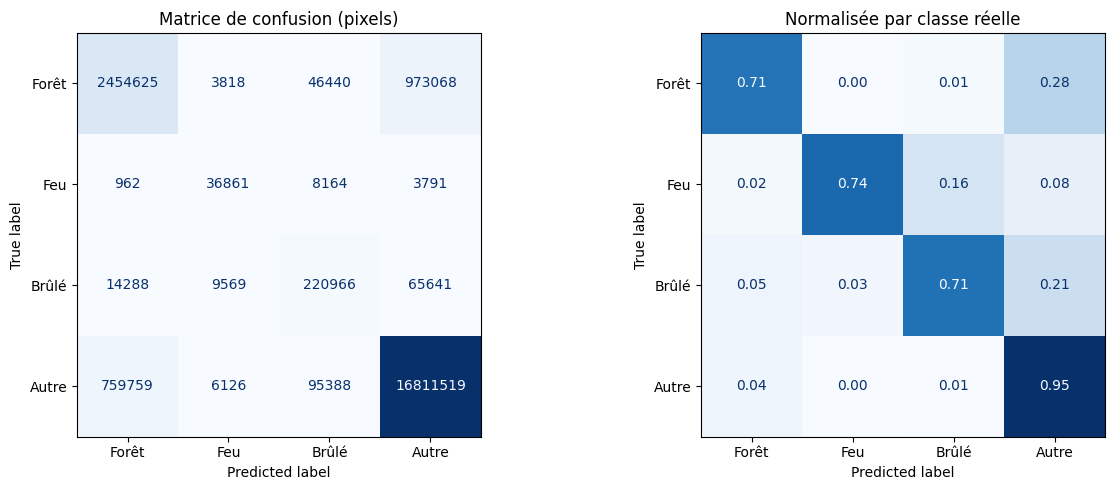

In [13]:
decision, tuning_table = tune_decisions(model, val_idx)
tuning_table.to_csv(OUTPUT / "validation_thresholds.csv", index=False)
display(tuning_table.round(4))
print("Paramètres figés :", decision)

# Illustration en validation : centrage sur un désaccord feu/brûlé.
example_found = False
for index in val_idx:
    probs = predict_probs(model, np.array([index]))[0]
    raw = decide(probs)
    target = Y[index]
    conflict = ((target == 1) & (raw == 2)) | ((target == 2) & (raw == 1))
    pixels = np.argwhere(conflict)
    if len(pixels):
        r, col = pixels[len(pixels) // 2]
        window = np.s_[max(0, r-20):r+21, max(0, col-20):col+21]
        fig, axes = plt.subplots(1, 4, figsize=(12, 3))
        axes[0].imshow(display_image(X[index])[window])
        axes[0].set_title("VIIRS")
        for ax, grid, title in zip(axes[1:], [target, raw, decide(probs, **decision)],
                                   ["Cible", "Argmax", "Réglé"]):
            ax.imshow(np.ma.array(grid[window], mask=target[window] == IGNORE),
                      cmap=CMAP, vmin=0, vmax=3, interpolation="nearest")
            ax.set_title(title)
        fig.suptitle(f"Exemple d’erreur en validation · événement {files.event.iloc[index]}")
        for ax in axes: ax.axis("off")
        fig.tight_layout()
        fig.savefig(OUTPUT / "validation_fire_burned_zoom.png", dpi=140)
        plt.show()
        example_found = True
        break
if not example_found:
    print("Aucune confusion feu/brûlé observée en validation avec argmax.")

Yt = Y[test_idx]
test_valid = Yt != IGNORE
test_probs = predict_probs(model, test_idx)
raw_cm = confusion(Yt[test_valid], decide(test_probs)[test_valid])
prediction = decide(test_probs, **decision)
del test_probs

cm = confusion(Yt[test_valid], prediction[test_valid])
s = class_scores(cm)
comparison = []
for label, matrix in [("argmax", raw_cm), ("validation", cm)]:
    stats = class_scores(matrix)
    comparison.append({"règle": label, "précision feu": stats["precision"][1],
                       "rappel feu": stats["recall"][1], "F1 feu": stats["f1"][1],
                       "IoU forêt": stats["iou"][0], "IoU feu": stats["iou"][1],
                       "IoU brûlé": stats["iou"][2], "feu → brûlé": matrix[1, 2],
                       "brûlé → feu": matrix[2, 1], "forêt → autre": matrix[0, 3],
                       "autre → forêt": matrix[3, 0]})
comparison = pd.DataFrame(comparison)
display(comparison)
comparison.to_csv(OUTPUT / "decision_comparison.csv", index=False)
baseline = float(np.mean(Yt[test_valid] == np.argmax(counts)))

scores = pd.DataFrame({"classe": CLASS_NAMES, "précision": s["precision"], "rappel": s["recall"],
                       "F1": s["f1"], "IoU": s["iou"], "pixels_test": s["support"]})
display(scores.round(4))

summary = pd.Series({
    "accuracy": s["accuracy"],
    "IoU moyen (4 classes)": np.nanmean(s["iou"]),
    "IoU moyen feu/brûlé": np.nanmean(s["iou"][FOCUS]),
    **{f"IoU {n.lower()}": v for n, v in zip(CLASS_NAMES, s["iou"])},
}, name="test")
display(summary.round(4).to_frame())
print(f"Référence « tout prédire {CLASS_NAMES[np.argmax(counts)]} » : {baseline:.2%} d'accuracy")

other_row = cm[OTHER] / cm[OTHER].sum()
print("Pixels réellement « Autre » prédits comme :", {n: round(float(v), 4) for n, v in zip(CLASS_NAMES, other_row)})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Matrice de confusion (pixels)")
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=CLASS_NAMES).plot(
    ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
axes[1].set_title("Normalisée par classe réelle")
plt.tight_layout()
plt.savefig(OUTPUT / "confusion_matrix.png", dpi=150)
plt.show()

### IoU par événement

Le test ne contient qu'une vingtaine d'événements : la moyenne globale peut cacher de grandes différences entre incendies. Le tableau donne l'IoU de chaque événement de test pour feu et brûlé (vide si la classe est absente de l'événement). Un IoU calculé sur très peu de pixels n'est pas significatif.

Le tableau supplémentaire mesure les erreurs sur les pixels « autre » urbains (13) et aquatiques (17).

In [14]:
event_of_test = files.event.iloc[test_idx].to_numpy()
rows = []
for ev in sorted(set(event_of_test)):
    sel = event_of_test == ev
    v = test_valid[sel]
    ev_scores = class_scores(confusion(Yt[sel][v], prediction[sel][v]))
    rows.append({"événement": ev, "dates": int(sel.sum()), "pixels_feu": int(ev_scores["support"][1]),
                 "pixels_brûlé": int(ev_scores["support"][2]),
                 "IoU feu": ev_scores["iou"][1], "IoU brûlé": ev_scores["iou"][2]})
per_event = pd.DataFrame(rows)
per_event.to_csv(OUTPUT / "per_event_iou.csv", index=False)
display(per_event.round(3))
print("IoU feu : médiane", round(per_event["IoU feu"].median(), 3), "| IoU brûlé : médiane", round(per_event["IoU brûlé"].median(), 3))

counts_by_cover = {13: np.zeros(4, dtype="int64"), 17: np.zeros(4, dtype="int64")}
for local, index in enumerate(test_idx):
    row = files.iloc[index]
    with rasterio.open(row.image) as day, rasterio.open(row.auxiliary) as aux:
        codes = landcover_codes(aligned_cover(day, aux, SIZE))
    for code, counts_by_class in counts_by_cover.items():
        selection = (codes == code) & (Y[index] == OTHER)
        counts_by_class += np.bincount(prediction[local][selection], minlength=4)
cover_rows = []
for code, name in [(13, "Urbain"), (17, "Eau")]:
    counts_by_class = counts_by_cover[code]
    total = int(counts_by_class.sum())
    cover_rows.append({"terrain": name, "pixels": total,
                       **{f"prédit {label}": int(n) for label, n in zip(CLASS_NAMES, counts_by_class)},
                       "taux prédit feu": counts_by_class[1] / total if total else np.nan})
cover_report = pd.DataFrame(cover_rows)
display(cover_report)
cover_report.to_csv(OUTPUT / "water_urban_errors.csv", index=False)

,événement,dates,pixels_feu,pixels_brûlé,IoU feu,IoU brûlé
0,20702159,1,82,337,0.470,0.614
1,20901111,1,56,656,0.276,0.386
2,20901127,1,60,742,0.284,0.407
3,21751303,31,1090,6355,0.486,0.451
4,21751305,3,111,663,0.252,0.184
5,21889779,33,3307,11366,0.530,0.515
6,21889943,36,4598,15185,0.527,0.297
7,21998023,6,172,10,0.328,0.000
8,21998264,15,1399,19765,0.529,0.430
9,24191376,8,221,2030,0.335,0.137


IoU feu : médiane 0.494 | IoU brûlé : médiane 0.407


,terrain,pixels,prédit Forêt,prédit Feu,prédit Brûlé,prédit Autre,taux prédit feu
0,Urbain,293101,6525,12,357,286207,0.000041
1,Eau,1964353,52889,21,4353,1907090,0.000011


## 12. Cartes de segmentation

Première date de test de trois événements différents, choisies sans regarder les scores. Les pixels gris clair sont ignorés dans la cible et dans la prédiction affichée. Le modèle prédit en réalité une classe pour tous les pixels ; l'affichage reprend le masque de la cible pour comparer sur les mêmes pixels. Ce sont des illustrations redimensionnées, pas des cartes géoréférencées.

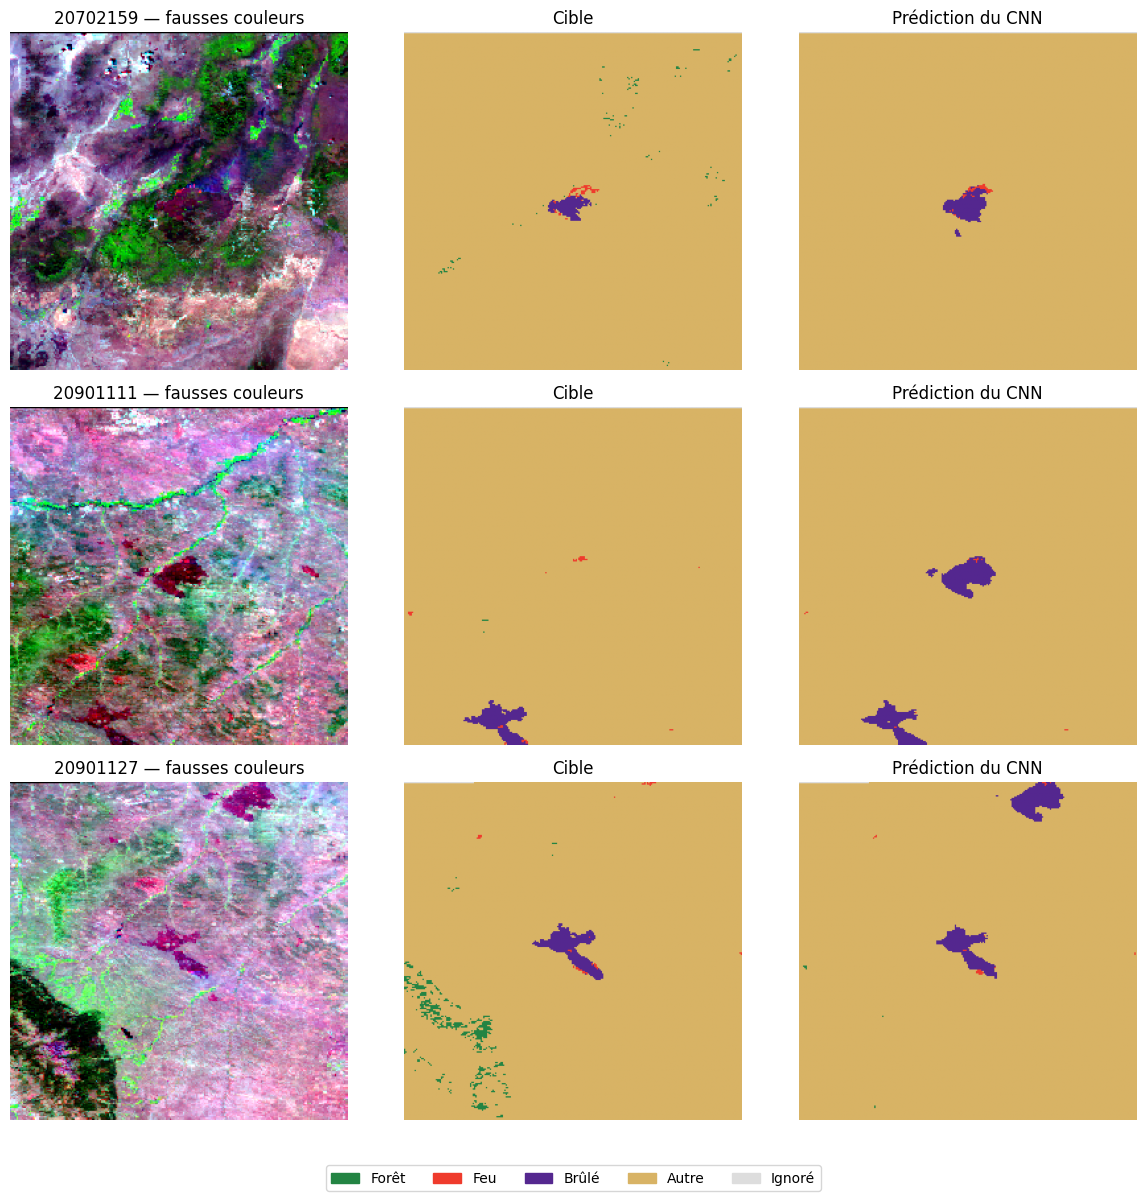

In [15]:
test_files = files.iloc[test_idx].reset_index(drop=True)
examples = test_files.drop_duplicates("event").index[:3].tolist()
fig, axes = plt.subplots(len(examples), 3, figsize=(12, 4 * len(examples)), squeeze=False)
for r, local_index in enumerate(examples):
    original = test_idx[local_index]
    axes[r, 0].imshow(display_image(X[original]))
    axes[r, 0].set_title(f"{test_files.event.iloc[local_index]} — fausses couleurs")
    axes[r, 1].imshow(np.ma.masked_equal(Y[original], IGNORE), cmap=CMAP, vmin=0, vmax=N_CLASSES - 1)
    axes[r, 1].set_title("Cible")
    axes[r, 2].imshow(np.ma.array(prediction[local_index], mask=~test_valid[local_index]),
                      cmap=CMAP, vmin=0, vmax=N_CLASSES - 1)
    axes[r, 2].set_title("Prédiction du CNN")
    for ax in axes[r]:
        ax.axis("off")
fig.legend(handles=legend, loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig(OUTPUT / "segmentation_maps.png", dpi=150)
plt.show()

## 13. Export du modèle et de sa règle de décision
Utiliser ensemble best_model.keras, normalization.npz, run_config.json et satfire_decision.py de la même exécution. La fonction decide applique les deux facteurs enregistrés dans le JSON. Le test de relecture vérifie les probabilités et les classes produites après export.

In [16]:
def clean(value):
    value = float(value)
    return value if np.isfinite(value) else None

scores.to_csv(OUTPUT / "test_metrics.csv", index=False)
summary.to_frame().to_csv(OUTPUT / "test_summary.csv")
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUTPUT / "confusion_matrix.csv")
test_files = files.iloc[test_idx].reset_index(drop=True)
test_files.to_csv(OUTPUT / "test_files.csv", index=False)
np.savez_compressed(OUTPUT / "test_masks.npz", target=Yt,
                    prediction=np.where(test_valid, prediction, IGNORE).astype("uint8"))
model.save(OUTPUT / "best_model.keras")

metrics = {"test_accuracy": s["accuracy"], "majority_baseline": baseline,
           "mean_iou_4_classes": clean(np.nanmean(s["iou"])),
           "mean_iou_fire_burned": clean(np.nanmean(s["iou"][FOCUS])),
           "class_iou": {n: clean(v) for n, v in zip(CLASS_NAMES, s["iou"])},
           "other_row_normalized": {n: clean(v) for n, v in zip(CLASS_NAMES, other_row)},
           "best_epoch": best_epoch, "epochs_run": len(history_table),
           "best_validation_fire_iou": float(history_table.val_fire_iou.max()),
           "training_minutes": training_minutes}
(OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2, allow_nan=False))
config = {"dataset": "z789456sx/ts-satfire", "seed": SEED, "data_fraction": DATA_FRACTION, "size": SIZE,
          "baseline_eligibility_size": BASELINE_SIZE, "epochs": EPOCHS, "early_stopping_patience": PATIENCE,
          "batch_size": BATCH_SIZE,
          "loss": f"weighted cross-entropy + {DICE_WEIGHT} * dice (fire, burned)",
          "architecture": "6 conv 3x3 blocks, dilation 1-2-4-8-16-1, BatchNorm, 1x1 softmax (4 classes)",
          "lr_schedule": "Adam 1e-3, ReduceLROnPlateau x0.5 patience 3",
          "prediction_rule": "pairwise_v1: argmax group, then adjusted fire vs burned or forest vs other",
          "decision": decision, "valid_landcover_codes": LANDCOVER_VALID_CODES,
          "cv_folds": CV_FOLDS if RUN_CV else None,
          "input_bands_one_based": [1, 2, 3, 4, 5, 6], "active_band": 7, "burned_band": 8, "landcover_band": 14,
          "forest_codes": LANDCOVER_FOREST_CODES, "landcover_fill_codes": LANDCOVER_FILL_CODES,
          "resampling": "nearest",
          "class_ids": {"0": "forest", "1": "fire", "2": "burned", "3": "other", "255": "ignore"},
          "date_filter": "both native-resolution label layers must contain positive annotations; "
                         "a date needs at least one forest, fire or burned pixel (same dates as version 3)",
          "tensorflow_version": tf.__version__, "rasterio_version": rasterio.__version__}
(OUTPUT / "run_config.json").write_text(json.dumps(config, indent=2))

reloaded = models.load_model(OUTPUT / "best_model.keras", compile=False)
probe = normalize(X[test_idx[:1]], mean, std)
np.testing.assert_allclose(model(probe, training=False).numpy(), reloaded(probe, training=False).numpy(), atol=1e-5)
del reloaded
print("Résultats principaux sauvegardés dans", OUTPUT)
(OUTPUT / "satfire_decision.py").write_text('import numpy as np\n\ndef decide(probs, fire_factor=1.0, forest_factor=1.0):\n    labels = np.argmax(probs, axis=-1).astype("uint8")\n    active_group = (labels == 1) | (labels == 2)\n    forest_group = ~active_group\n    if fire_factor != 1.0:\n        fire_wins = probs[..., 1] * fire_factor >= probs[..., 2]\n        labels[active_group] = np.where(fire_wins[active_group], 1, 2)\n    if forest_factor != 1.0:\n        forest_wins = probs[..., 0] * forest_factor >= probs[..., 3]\n        labels[forest_group] = np.where(forest_wins[forest_group], 0, 3)\n    return labels\n', encoding="utf-8")
from importlib.util import spec_from_file_location, module_from_spec
spec = spec_from_file_location("satfire_decision", OUTPUT / "satfire_decision.py")
deployment = module_from_spec(spec)
spec.loader.exec_module(deployment)
saved_config = json.loads((OUTPUT / "run_config.json").read_text())
with np.load(OUTPUT / "normalization.npz") as stats:
    deploy_probe = normalize(X[test_idx[:1]], stats["mean"], stats["std"])
deploy_model = models.load_model(OUTPUT / "best_model.keras", compile=False)
actual = deployment.decide(np.asarray(deploy_model(deploy_probe, training=False)), **saved_config["decision"])
np.testing.assert_array_equal(actual, prediction[:1])
del deploy_model


Résultats principaux sauvegardés dans /kaggle/working/satfire_v5_results


## 14. Point de reprise facultatif
Activer SAVE_CHECKPOINT pour archiver les données brutes et masques v5 en vue d’une reprise de la validation croisée. Prévoir plusieurs Go de stockage.

In [17]:
if SAVE_CHECKPOINT:
    import os, pickle

    checkpoint = OUTPUT.with_name(OUTPUT.name + "_checkpoint")
    checkpoint.mkdir(parents=True)

    np.save(checkpoint / "X.npy", X)
    np.save(checkpoint / "Y.npy", Y)
    files.to_pickle(checkpoint / "files.pkl")
    state = {"format": "satfire_v5_raw", "events": events, "baseline_events": list(baseline_events), "split": split,
             "train_idx": train_idx, "val_idx": val_idx, "test_idx": test_idx,
             "train_events": train_events, "val_events": val_events, "test_events": test_events,
             "mean": mean, "std": std, "class_weights": class_weights,
             "best_epoch": best_epoch, "training_minutes": training_minutes}
    with open(checkpoint / "state.pkl", "wb") as f:
        pickle.dump(state, f)
    shutil.copytree(OUTPUT, checkpoint / "results", dirs_exist_ok=True)

    archive = shutil.make_archive(str(checkpoint), "zip", root_dir=checkpoint)
    print(f"Point de reprise enregistré : {os.path.getsize(archive) / 1024**3:.2f} Go")
    display(FileLink(archive))

## 15. Reprise facultative de la validation croisée
Dans une nouvelle session, exécuter les sections 1 à 3, renseigner RESTORE_FROM dans les paramètres avec le répertoire du checkpoint v5, puis exécuter cette cellule, la validation croisée et la sauvegarde finale. Le checkpoint contient les six bandes brutes.

In [18]:
import os, pickle

if RESTORE_FROM is not None:
    ckpt = Path(RESTORE_FROM)
    if not (ckpt / "state.pkl").exists():
        raise FileNotFoundError(f"state.pkl introuvable dans {ckpt}")
    X = np.load(ckpt / "X.npy")
    Y = np.load(ckpt / "Y.npy")
    files = pd.read_pickle(ckpt / "files.pkl")
    with open(ckpt / "state.pkl", "rb") as f:
        state = pickle.load(f)
    if state.pop("format", None) != "satfire_v5_raw":
        raise ValueError("Un checkpoint v5 avec les observations brutes est requis.")
    globals().update(state)
    if (ckpt / "results").exists():
        shutil.copytree(ckpt / "results", OUTPUT, dirs_exist_ok=True)
    print("Restauré :", X.shape, Y.shape, "|", len(events), "événements")
else:
    print("Aucune restauration demandée (RESTORE_FROM = None).")

Aucune restauration demandée (RESTORE_FROM = None).


## 16. Validation croisée facultative
Chaque pli recalcule sa normalisation, ses poids de classes et ses seuils sur les événements appropriés. Les fichiers de pli portent son numéro. Le modèle principal et ses paramètres ont été exportés avant cette section.

In [19]:
cv_table = pd.DataFrame()
if RUN_CV:
    cv_rows = []
    main_mean, main_std = mean, std
    try:
        folds = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
        for fold, (pool, held_out) in enumerate(folds.split(events), 1):
            fold_train, fold_val = train_test_split([events[i] for i in pool], test_size=0.15, random_state=SEED)
            fold_test = [events[i] for i in held_out]
            tr, va, te = (np.flatnonzero(files.event.isin(group)) for group in (fold_train, fold_val, fold_test))
            mean, std = channel_statistics(X, tr)
            net, _ = train_model(tr, va, f"cv{fold}", verbose=0)
            fold_rule, _ = tune_decisions(net, va)
            matrix = np.zeros((4, 4), dtype=np.int64)
            for start in range(0, len(te), BATCH_SIZE):
                batch = te[start:start + BATCH_SIZE]
                truth = Y[batch]
                valid = truth != IGNORE
                pred = decide(predict_probs(net, batch), **fold_rule)
                matrix += confusion(truth[valid], pred[valid])
            score = class_scores(matrix)
            cv_rows.append({"pli": fold, **{f"IoU {label.lower()}": score["iou"][i]
                                           for i, label in enumerate(CLASS_NAMES)},
                            "accuracy": score["accuracy"], **fold_rule})
            np.savez(OUTPUT / f"normalization_cv{fold}.npz", mean=mean, std=std)
            cv_table = pd.DataFrame(cv_rows)
            cv_table.to_csv(OUTPUT / "cv_results.csv", index=False)
            display(cv_table.tail(1))
            del net
    finally:
        mean, std = main_mean, main_std

## 17. Archive finale

L'archive ZIP contient tous les fichiers du dossier de sortie : le meilleur modèle, les statistiques de normalisation, les découpages, les métriques, les figures, les masques de test et les résultats de la validation croisée.

In [20]:
if not cv_table.empty:
    cols = ["IoU forêt", "IoU feu", "IoU brûlé", "IoU autre", "accuracy"]
    pd.DataFrame({"moyenne": cv_table[cols].mean(), "écart-type": cv_table[cols].std()}).to_csv(
        OUTPUT / "cv_summary.csv")
zip_path = shutil.make_archive(str(OUTPUT), "zip", root_dir=OUTPUT)
print(f"Durée totale de la session : {(time.perf_counter() - started) / 60:.1f} min")
display(FileLink(zip_path))

Durée totale de la session : 61.9 min


/kaggle/working/satfire_v5_results.zip